# 02 · Exploración y selección de la ingeniería de características

**Proyecto #2 – Pipeline de Machine Learning · Predict Future Sales (Kaggle)**

Este notebook continúa el EDA (`01_exploratory_data_analysis.ipynb`) y decide **qué variables y qué
transformaciones** usará el modelo de *forecasting*. No construye todavía el pipeline (eso es el
notebook 03): aquí se analiza, se prueba y se justifica cada decisión con los datos.

| Sección | Punto del enunciado |
|---|---|
| 1. Dataset base mensual (grid con ceros) | 1.a – cargar el dataset de los notebooks anteriores, nivel mensual tienda-producto |
| 2. Selección de *lags* | 1.a – qué rezagos usar, sin fuga de información |
| 3. Los 6 procesos de ingeniería de características | 1.b – i a vi, con su criterio de selección |
| 4. Lista final de variables y mapeos | 1.c – proceso escrito: variables por transformación y mecanismos de mapeo |

**Enfoque de forecasting con variables exógenas.** En lugar de ajustar una serie de tiempo por cada
par tienda-producto (más de 400 mil series, la mayoría casi vacías), se usa un **modelo global de
regresión sobre rezagos**: cada fila es un par *(mes, tienda, producto)* y el modelo aprende de
todas las series a la vez. La historia propia de la serie entra como *lags* (la parte
autorregresiva, como en un ARIMA) y la **tienda y el producto entran como variables exógenas**:
identificadores, atributos (ciudad, tipo de tienda, categoría), historia agregada por tienda /
producto / categoría y banderas de novedad. Es la formulación de un *ARX global* (autorregresivo con
exógenas), que permite pronosticar incluso pares y productos sin historia.

## 0. Configuración

In [1]:
import os

os.environ["LOGURU_LEVEL"] = "WARNING"  # oculta los mensajes informativos del paquete

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

from feature_engine.encoding import MeanEncoder, OneHotEncoder
from feature_engine.imputation import AddMissingIndicator, CategoricalImputer, MeanMedianImputer
from feature_engine.outliers import Winsorizer
from feature_engine.transformation import LogCpTransformer
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from predict_future_sales.config import PROCESSED_DATA_DIR
from predict_future_sales.dataset import load_raw_data
import predict_future_sales.features as pf
from predict_future_sales.plots import COLOR_ACCENT, COLOR_MAIN, COLOR_MUTED, save_fig, set_style

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
TRAIN_END, VAL_START = 26, 27  # partición secuencial del enunciado: 0-26 entrenamiento, 27-33 validación

## 1. Dataset base: grid mensual tienda × producto con ceros

Se carga el dataset generado en el notebook 01 (`data/processed/monthly_shop_item.csv`): ventas
mensuales netas por par tienda-producto, ya con la limpieza del EDA (duplicados eliminados, precio
negativo imputado, 2 transacciones extremas fuera y tiendas duplicadas 0→57, 1→58, 11→10
unificadas). Ese archivo **solo contiene los pares que vendieron algo** en el mes.

El enunciado recomienda rellenar con cero los meses sin ventas. Se usa el mismo criterio con el que
Kaggle armó `test.csv` (42 tiendas × 5,100 productos = producto cartesiano): **para cada mes, todas
las combinaciones entre las tiendas activas y los productos activos de ese mes**, con
`item_cnt_month = 0` donde no hubo venta (`pf.build_monthly_grid`). El objetivo se recorta a
**[0, 20]**, igual que la evaluación de la competencia (decisión del EDA, sección 10).

In [2]:
# Dataset de los notebooks anteriores + catálogos originales
monthly = pd.read_csv(PROCESSED_DATA_DIR / "monthly_shop_item.csv")
raw = load_raw_data()
items, test = raw["items"], raw["test"]
print(f"monthly_shop_item: {monthly.shape[0]:,} filas · columnas {list(monthly.columns)}")
monthly.head()

monthly_shop_item: 1,609,123 filas · columnas ['date_block_num', 'shop_id', 'item_id', 'item_cnt_month', 'revenue']


,date_block_num,shop_id,item_id,item_cnt_month,revenue
0,0,2,27,1.0000,"2,499.0000"
1,0,2,33,1.0000,499.0000
2,0,2,317,1.0000,299.0000
3,0,2,438,1.0000,299.0000
4,0,2,471,2.0000,798.0000


In [3]:
# Grid mensual con ceros (tiendas activas × productos activos de cada mes), objetivo recortado a [0, 20]
grid = pf.build_monthly_grid(monthly)

# Control: la suma del grid coincide con la suma de las ventas mensuales recortadas
assert np.isclose(grid[pf.TARGET].sum(), monthly[pf.TARGET].clip(0, 20).sum())

resumen = pd.Series(
    {
        "filas del grid": len(grid),
        "meses": grid.date_block_num.nunique(),
        "pares con venta (> 0)": int((grid[pf.TARGET] > 0).sum()),
        "% filas en cero": (grid[pf.TARGET] == 0).mean() * 100,
        "media de item_cnt_month": grid[pf.TARGET].mean(),
        "filas entrenamiento (meses 0-26)": int((grid.date_block_num <= TRAIN_END).sum()),
        "filas validación (meses 27-33)": int((grid.date_block_num >= VAL_START).sum()),
        "filas test (mes 34)": len(test),
        "memoria del grid (MB)": grid.memory_usage().sum() / 1e6,
    }
)
resumen.to_frame("valor").style.format("{:,.2f}")

,valor
filas del grid,"10,913,804.00"
meses,34.00
pares con venta (> 0),"1,605,625.00"
% filas en cero,85.29
media de item_cnt_month,0.30
filas entrenamiento (meses 0-26),"9,299,440.00"
filas validación (meses 27-33),"1,614,364.00"
filas test (mes 34),"214,200.00"
memoria del grid (MB),87.31


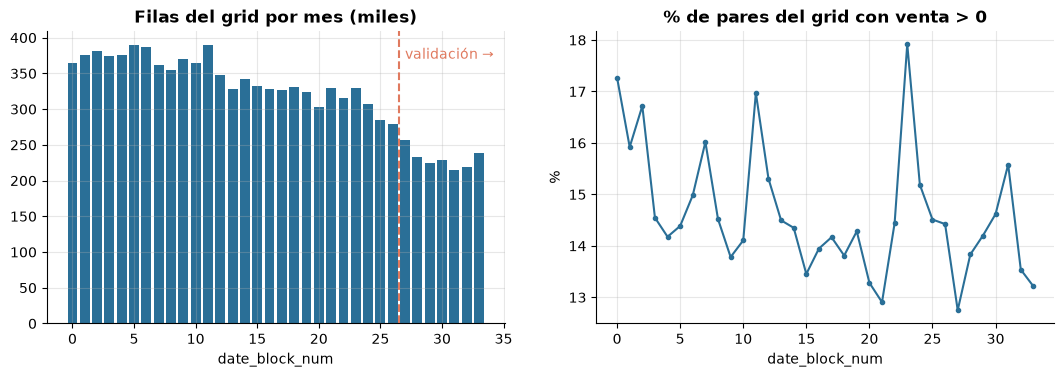

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_month = grid.groupby("date_block_num").agg(filas=(pf.TARGET, "size"), con_venta=(pf.TARGET, lambda s: (s > 0).mean()))
axes[0].bar(by_month.index, by_month.filas / 1e3, color=COLOR_MAIN)
axes[0].axvline(26.5, color=COLOR_ACCENT, ls="--")
axes[0].text(27, by_month.filas.max() / 1e3 * 0.95, "validación →", color=COLOR_ACCENT)
axes[0].set(title="Filas del grid por mes (miles)", xlabel="date_block_num")
axes[1].plot(by_month.index, by_month.con_venta * 100, color=COLOR_MAIN, marker="o", ms=3)
axes[1].set(title="% de pares del grid con venta > 0", xlabel="date_block_num", ylabel="%")
save_fig(fig, "p2_02a_grid_por_mes")
plt.show()

**Interpretación.** El grid tiene **10,913,804 filas** (34 meses): 9,299,440 para entrenamiento (meses 0-26, 85 %) y 1,614,364 para validación (meses 27-33, 15 %); en filas, la partición queda cerca del 80/20 del enunciado (en meses es 27/7). El **85.3 % de las filas son cero**: en un mes típico solo entre el 12.8 % y el 17.9 % de las combinaciones tienda × producto activas vende algo (media 0.298 unidades por fila). Esto es justo lo que se verá en el test: muchos pares sin venta, por lo que entrenar solo con los pares que vendieron (1.6 millones de filas) enseñaría al modelo un mundo sin ceros y sobreestimaría. El número de filas por mes baja de ~365-390 mil en 2013 a ~220-240 mil en 2015 porque cada mes hay menos productos activos (8,115 en enero 2013 frente a 5,413 en octubre 2015), coherente con la tendencia decreciente del EDA. La suma del objetivo del grid coincide con la suma de las ventas mensuales recortadas (control `assert`), así que los ceros agregados no alteran las ventas reales.

## 2. Selección de los *lags*

### 2.1 Cómo se construye un lag sin fuga de información

Los rezagos se generan con el transformador `SalesHistoryFeatures` (`predict_future_sales/features.py`):
guarda la historia mensual y, para una fila del mes `m`, consulta **únicamente los meses `m − k`**
(`k ≥ 1`). Reglas:

- el par no aparece en la historia del mes `m − k` → **0** (no vendió ese mes);
- `m − k < 0` (antes de enero 2013) → **NaN** (no hay información; se imputa en la sección 3.i);
- para el **mes 34** de `test.csv` los lags salen de los meses 33, 32, 31, … tal como pide el enunciado.

Además del lag del propio par, se calculan lags **agregados** (promedio por par del grupo) a nivel
producto, categoría, tienda y tienda × categoría: son la forma en que **tienda y producto entran
como variables exógenas** y dan información a los pares sin historia (48 % del test, según el EDA).

Primero se verifica que no exista fuga: el lag 1 calculado por el transformador debe ser idéntico al
valor del mismo par en el mes anterior calculado "a mano".

In [5]:
# Candidatos amplios para el análisis: lags 1..12 del par y del producto
cand = pf.SalesHistoryFeatures(
    history=monthly, items=items,
    pair_lags=tuple(range(1, 13)), item_lags=tuple(range(1, 13)),
    cat_lags=(1, 2, 3, 6, 12), shop_lags=(1, 2, 3, 6, 12), shop_cat_lags=(1, 2, 3, 6, 12),
).fit(grid[pf.KEYS])
F = cand.transform(grid[pf.KEYS])
F[pf.TARGET] = grid[pf.TARGET].to_numpy()

# Verificación de no-fuga 1: cnt_lag_1 == valor del par en el mes anterior (calculado a mano)
prev = grid.assign(date_block_num=grid.date_block_num + 1).rename(columns={pf.TARGET: "manual"})
check = F[pf.KEYS].merge(prev, on=pf.KEYS, how="left")["manual"].fillna(0)
check[F.date_block_num.to_numpy() == 0] = np.nan  # mes 0 no tiene mes anterior
assert np.allclose(F["cnt_lag_1"].fillna(-1), check.fillna(-1)), "fuga o error en cnt_lag_1"

# Verificación de no-fuga 2: historia truncada. Los lags del mes 30 deben ser idénticos si la
# historia solo llega hasta el mes 29 (nada del mes 30 o posterior se usa).
rows30 = grid.loc[grid.date_block_num == 30, pf.KEYS]
trunc = pf.SalesHistoryFeatures(history=monthly[monthly.date_block_num < 30], items=items,
                                pair_lags=tuple(range(1, 13)), item_lags=tuple(range(1, 13)),
                                cat_lags=(1, 2, 3, 6, 12), shop_lags=(1, 2, 3, 6, 12),
                                shop_cat_lags=(1, 2, 3, 6, 12)).fit(rows30)
pd.testing.assert_frame_equal(trunc.transform(rows30), F.loc[rows30.index, F.columns.drop(pf.TARGET)],
                              check_dtype=False)
print("OK: sin fuga de información (lag 1 coincide y la historia futura no altera las variables)")

OK: sin fuga de información (lag 1 coincide y la historia futura no altera las variables)


### 2.2 Relación de cada lag con las ventas

Correlación de Pearson entre `item_cnt_month` y cada rezago, usando los meses 12-33 (donde todos
los rezagos hasta 12 existen) para que todos se comparen sobre las mismas filas.

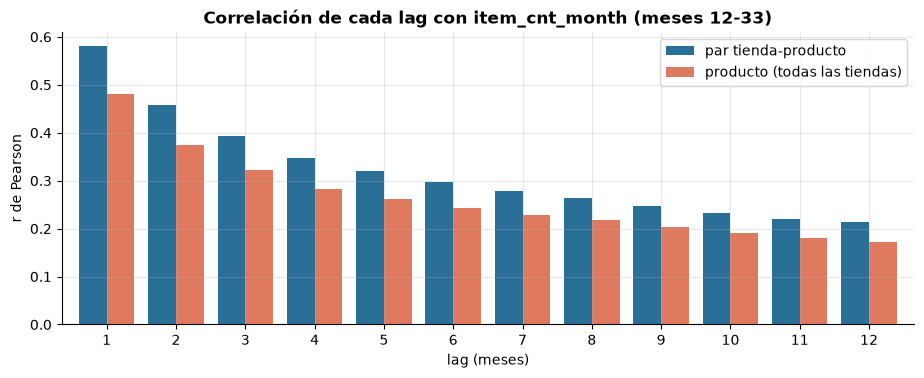

lag,1,2,3,4,5,6,7,8,9,10,11,12
par tienda-producto,0.5813,0.4572,0.3939,0.3467,0.3196,0.2976,0.2790,0.2644,0.2480,0.2328,0.2208,0.2133
producto (todas las tiendas),0.4809,0.3742,0.3227,0.2822,0.2611,0.2431,0.2282,0.2173,0.2040,0.1901,0.1799,0.1724


In [6]:
sub = F[F.date_block_num >= 12]
lags = range(1, 13)
corr = pd.DataFrame(
    {
        "par tienda-producto": [sub[f"cnt_lag_{k}"].corr(sub[pf.TARGET]) for k in lags],
        "producto (todas las tiendas)": [sub[f"item_cnt_lag_{k}"].corr(sub[pf.TARGET]) for k in lags],
    },
    index=pd.Index(lags, name="lag"),
)
fig, ax = plt.subplots(figsize=(11, 3.8))
corr.plot.bar(ax=ax, color=[COLOR_MAIN, COLOR_ACCENT], width=0.8)
ax.set(title="Correlación de cada lag con item_cnt_month (meses 12-33)", ylabel="r de Pearson", xlabel="lag (meses)")
ax.tick_params(axis="x", rotation=0)
save_fig(fig, "p2_02b_correlacion_lags")
plt.show()
corr.T

In [7]:
# Correlación de los lags agregados (tienda, categoría, tienda × categoría) con el objetivo
agg_cols = [c for c in F.columns if c.startswith(("cat_cnt", "shop_cnt", "shop_cat_cnt"))]
sub[agg_cols].corrwith(sub[pf.TARGET]).sort_values(ascending=False).to_frame("r con item_cnt_month")

,r con item_cnt_month
shop_cat_cnt_lag_1,0.4375
shop_cat_cnt_lag_2,0.4195
shop_cat_cnt_lag_3,0.4097
shop_cat_cnt_lag_6,0.3693
cat_cnt_lag_1,0.3259
shop_cat_cnt_lag_12,0.3150
cat_cnt_lag_2,0.3129
cat_cnt_lag_3,0.3078
cat_cnt_lag_6,0.2766
cat_cnt_lag_12,0.2254


**Interpretación.** Ambas pruebas de no-fuga pasaron: el lag 1 del transformador es idéntico al valor del mes anterior calculado a mano y, con la historia cortada en el mes 29, las variables del mes 30 no cambian en absolutamente nada. La correlación con las ventas **decrece de forma monótona con la distancia**: 0.58 en el lag 1, 0.46 en el lag 2, 0.39 en el lag 3, 0.30 en el lag 6 y 0.21 en el lag 12 (par tienda-producto); el nivel producto sigue el mismo patrón un poco más abajo (0.48 → 0.17). No aparece un repunte claro en el lag 12 en la correlación global porque la mayoría de los meses no son diciembre; la estacionalidad anual que mostró la ACF del EDA (lag 12 significativo en la serie diferenciada, +60 % en diciembre) afecta a pocos meses por año. Entre los agregados, la historia **tienda × categoría** es la más informativa (0.44), seguida de la categoría (0.33); la tienda sola aporta menos (0.17), lo que indica que importa más *qué* se vende que *dónde*.

### 2.3 Prueba empírica: ¿qué conjunto de lags predice mejor?

La correlación mide cada lag por separado; un lag puede estar correlacionado y aun así no aportar
nada nuevo (redundante con el lag 1). Para decidir se entrena un mismo modelo rápido (LightGBM con
parámetros fijos) en los meses **0-26** y se mide el **RMSE en validación (meses 27-33)**,
cambiando solo el conjunto de lags. Como referencia se incluyen dos pronósticos ingenuos.

In [8]:
train_F = F[F.date_block_num <= TRAIN_END]
val_F = F[F.date_block_num >= VAL_START]
y_val = val_F[pf.TARGET].to_numpy()


def rmse(pred, y=y_val):
    return float(np.sqrt(np.mean((np.clip(pred, 0, 20) - y) ** 2)))


def quick_lgbm(cols, start=0):
    tr = train_F[train_F.date_block_num >= start]
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=127, subsample=0.5,
                              subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE,
                              n_jobs=-1, verbose=-1)
    model.fit(tr[cols], tr[pf.TARGET])
    return rmse(model.predict(val_F[cols])), model


fixed = ["item_category_id", "shop_id", "item_price_last", "item_is_new", "pair_is_new",
         "item_age", "pair_age", "month", "days_in_month",
         "cat_cnt_lag_1", "cat_cnt_lag_2", "cat_cnt_lag_12", "shop_cnt_lag_1", "shop_cnt_lag_2",
         "shop_cnt_lag_12", "shop_cat_cnt_lag_1", "shop_cat_cnt_lag_2", "shop_cat_cnt_lag_12"]


def lag_cols(ks):
    return [f"cnt_lag_{k}" for k in ks] + [f"item_cnt_lag_{k}" for k in ks]


experiments = {
    "lags 1": (lag_cols([1]), 0),
    "lags 1, 2, 3": (lag_cols([1, 2, 3]), 0),
    "lags 1, 2, 3, 6, 12": (lag_cols([1, 2, 3, 6, 12]), 0),
    "lags 1, 2, 3, 4, 5, 6, 9, 12": (lag_cols([1, 2, 3, 4, 5, 6, 9, 12]), 0),
    "lags 1, 2, 3, 6 (sin 12)": (lag_cols([1, 2, 3, 6]), 0),
    "lags 1, 2, 3, 6, 12 · entrenando meses 12-26": (lag_cols([1, 2, 3, 6, 12]), 12),
    "lags 1, 2, 3, 6, 12 + item_id crudo": (lag_cols([1, 2, 3, 6, 12]) + ["item_id"], 0),
}
rows = [
    {"experimento": "ingenuo: predecir 0", "RMSE validación": rmse(np.zeros(len(val_F)))},
    {"experimento": "ingenuo: repetir el mes anterior (lag 1)", "RMSE validación": rmse(val_F.cnt_lag_1.fillna(0))},
]
models = {}
for name, (cols, start) in experiments.items():
    score, models[name] = quick_lgbm(fixed + cols, start)
    rows.append({"experimento": name, "RMSE validación": score})
lag_results = pd.DataFrame(rows).set_index("experimento")
lag_results

,RMSE validación
experimento,
ingenuo: predecir 0,1.1159
ingenuo: repetir el mes anterior (lag 1),1.0373
lags 1,0.8220
"lags 1, 2, 3",0.8201
"lags 1, 2, 3, 6, 12",0.8182
"lags 1, 2, 3, 4, 5, 6, 9, 12",0.8195
"lags 1, 2, 3, 6 (sin 12)",0.8170
"lags 1, 2, 3, 6, 12 · entrenando meses 12-26",0.8252
"lags 1, 2, 3, 6, 12 + item_id crudo",0.8229


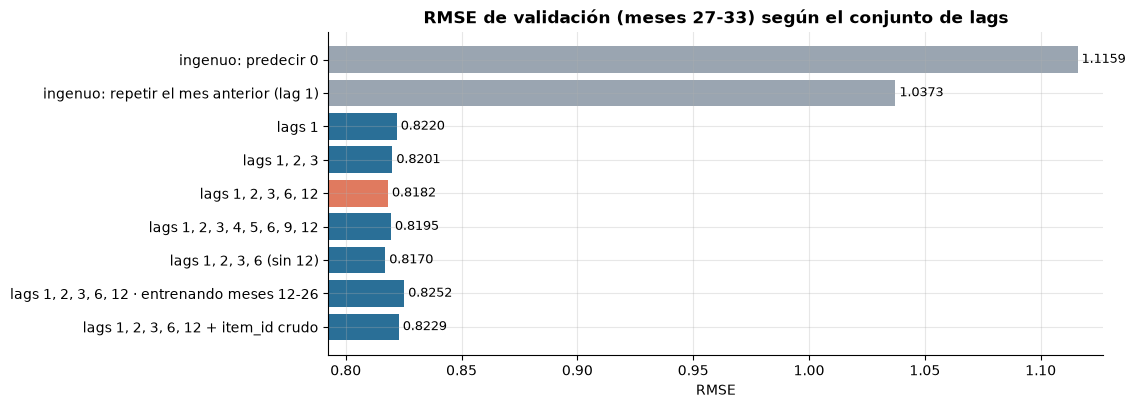

,% de la ganancia
cnt_lag_1,48.2329
item_cnt_lag_1,7.9129
shop_cat_cnt_lag_1,4.3616
item_category_id,4.2272
item_price_last,3.4071
shop_cat_cnt_lag_2,3.1454
month,3.1217
cat_cnt_lag_1,2.7898
cat_cnt_lag_2,2.4316
item_cnt_lag_2,2.0342


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
lr = lag_results["RMSE validación"].iloc[::-1]
colors = [COLOR_ACCENT if i == "lags 1, 2, 3, 6, 12" else (COLOR_MUTED if "ingenuo" in i else COLOR_MAIN) for i in lr.index]
ax.barh(lr.index, lr.values, color=colors)
ax.set_xlim(lr.min() * 0.97, lr.max() * 1.01)
for y, v in enumerate(lr.values):
    ax.text(v, y, f" {v:.4f}", va="center", fontsize=9)
ax.set(title="RMSE de validación (meses 27-33) según el conjunto de lags", xlabel="RMSE")
save_fig(fig, "p2_02c_rmse_lags")
plt.show()

# Importancia (ganancia) del modelo con los lags elegidos
best_cols = fixed + lag_cols([1, 2, 3, 6, 12])
imp = pd.Series(models["lags 1, 2, 3, 6, 12"].booster_.feature_importance("gain"), index=best_cols)
(imp / imp.sum() * 100).sort_values(ascending=False).head(15).to_frame("% de la ganancia")

**Decisión sobre los lags.** Todos los modelos con lags reducen el RMSE en ~21 % frente al mejor pronóstico ingenuo (1.037 → ~0.82): la historia propia del par concentra el 48 % de la ganancia del modelo y el lag 1 del producto otro 8 %. Pasar de solo el lag 1 (0.8220) a los lags 1, 2, 3 (0.8201) y a 1, 2, 3, 6, 12 (0.8182) mejora de forma consistente; agregar 4, 5 y 9 no ayuda (0.8195): son redundantes con sus vecinos. Quitar el lag 12 da 0.8170, una diferencia de 0.001 que está dentro de la variación entre corridas (en una prueba previa con los mismos datos la diferencia fue en sentido contrario). **Se conservan los lags 1, 2, 3, 6 y 12** por una razón de negocio: la validación (abril-octubre 2015) no incluye noviembre ni diciembre, justamente los meses donde la estacionalidad anual pesa más, y el mes a predecir es noviembre: el lag 12 le da al modelo las ventas de noviembre 2014. También se confirma entrenar con **los meses 0-26 completos** (0.8182) y no solo con 12-26 (0.8252): más meses compensan los lags faltantes, que se imputan. El `item_id` crudo empeora el resultado (0.8229): el número de producto no tiene un orden con significado y el modelo memoriza productos; el producto entra mejor por su historia, categoría y banderas.

## 3. Los 6 procesos de ingeniería de características

Desde aquí se trabaja con los lags elegidos. Todas las estadísticas (medianas, medias por
categoría, percentiles, medias y desviaciones del escalado) se **aprenden solo con los meses de
entrenamiento (0-26)** y se aplican a validación y test, igual que lo hará el pipeline del notebook
03. En esta sección solo se **demuestra** cada operación con `feature-engine` / `scikit-learn`; el
operador final se arma en el siguiente notebook.

In [10]:
# Variables base con los lags elegidos (sección 2) + atributos de tienda y categoría vía Mapper
maps = pf.build_mappings(raw["items"], raw["categories"], raw["shops"])
history = pf.SalesHistoryFeatures(monthly, items, pf.PAIR_LAGS, pf.ITEM_LAGS, pf.GROUP_LAGS,
                                  pf.GROUP_LAGS, pf.GROUP_LAGS).fit(grid[pf.KEYS])
mappers = [pf.Mapper(["shop_id"], maps["city"], ["city"]),
           pf.Mapper(["shop_id"], maps["shop_type"], ["shop_type"]),
           pf.Mapper(["item_category_id"], maps["category_group"], ["category_group"])]


def base_features(keys):
    out = history.transform(keys)
    for m in mappers:
        out = m.transform(out)
    return out


del F, sub, train_F, val_F, models, cand, trunc, prev, check  # libera memoria del análisis de lags
X_train = base_features(grid.loc[grid.date_block_num <= TRAIN_END, pf.KEYS])
y_train = grid.loc[X_train.index, pf.TARGET]
X_test = base_features(test.assign(date_block_num=pf.TEST_BLOCK)[pf.KEYS])
print(f"X_train: {X_train.shape} · X_test (mes 34): {X_test.shape}")
X_train.head()

X_train: (9299440, 33) · X_test (mes 34): (214200, 33)


,date_block_num,shop_id,item_id,item_category_id,cnt_lag_1,cnt_lag_2,cnt_lag_3,cnt_lag_6,cnt_lag_12,item_cnt_lag_1,item_cnt_lag_2,item_cnt_lag_3,item_cnt_lag_6,item_cnt_lag_12,cat_cnt_lag_1,cat_cnt_lag_2,cat_cnt_lag_12,shop_cnt_lag_1,shop_cnt_lag_2,shop_cnt_lag_12,shop_cat_cnt_lag_1,shop_cat_cnt_lag_2,shop_cat_cnt_lag_12,item_price_last,item_is_new,pair_is_new,item_age,pair_age,month,days_in_month,city,shop_type,category_group
0,0,2,19,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,0,31,Adigueya,Centro comercial,Cine
1,0,2,27,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,0,31,Adigueya,Centro comercial,Juegos
2,0,2,28,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,0,31,Adigueya,Centro comercial,Juegos PC
3,0,2,29,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,0,31,Adigueya,Centro comercial,Juegos
4,0,2,32,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,0,31,Adigueya,Centro comercial,Cine


### 3.i Imputación de variables numéricas

**¿Hay faltantes?** Sí, y son reales (no hace falta forzarlos):

- **lags** de meses anteriores a enero 2013 (`m − k < 0`): el lag 12 no existe en los meses 0-11;
- **`item_price_last`**: un producto que nunca se ha vendido no tiene precio previo (7 % del test
  son productos nuevos).

In [11]:
na = pd.DataFrame({
    "% NaN entrenamiento": X_train[pf.NUM_IMPUTE_VARS].isna().mean() * 100,
    "% NaN test (mes 34)": X_test[pf.NUM_IMPUTE_VARS].isna().mean() * 100,
})
na[na.sum(axis=1) > 0]

,% NaN entrenamiento,% NaN test (mes 34)
cnt_lag_1,3.9268,0.0000
cnt_lag_2,7.9672,0.0000
cnt_lag_3,12.0738,0.0000
cnt_lag_6,24.3317,0.0000
cnt_lag_12,48.2686,0.0000
item_cnt_lag_1,3.9268,0.0000
item_cnt_lag_2,7.9672,0.0000
item_cnt_lag_3,12.0738,0.0000
item_cnt_lag_6,24.3317,0.0000
item_cnt_lag_12,48.2686,0.0000


In [12]:
# Alternativas: media vs mediana (aprendidas en entrenamiento)
alt = pd.DataFrame({
    "media": X_train[pf.NUM_IMPUTE_VARS].mean(),
    "mediana": X_train[pf.NUM_IMPUTE_VARS].median(),
    "asimetría": X_train[pf.NUM_IMPUTE_VARS].skew(),
})
alt.loc[["cnt_lag_1", "cnt_lag_12", "item_cnt_lag_1", "shop_cnt_lag_1", "item_price_last"]]

,media,mediana,asimetría
cnt_lag_1,0.2992,0.0000,9.2948
cnt_lag_12,0.2442,0.0000,10.0790
item_cnt_lag_1,0.3012,0.0870,9.4575
shop_cnt_lag_1,0.3025,0.2383,2.1825
item_price_last,637.2280,299.0000,11.0026


In [13]:
# Operación elegida: indicador de faltante (para lags del par y precio) + imputación por mediana
indicator = AddMissingIndicator(variables=pf.MISSING_INDICATOR_VARS).fit(X_train)
num_imputer = MeanMedianImputer(imputation_method="median", variables=pf.NUM_IMPUTE_VARS)
num_imputer.fit(indicator.transform(X_train))
imp_train = num_imputer.transform(indicator.transform(X_train))
imp_test = num_imputer.transform(indicator.transform(X_test))

print("Valores de imputación aprendidos (mediana de entrenamiento):")
print({k: round(v, 3) for k, v in num_imputer.imputer_dict_.items() if k in ("cnt_lag_1", "cnt_lag_12", "item_cnt_lag_1", "shop_cnt_lag_1", "item_price_last")})
print("Indicadores agregados:", [c for c in imp_train.columns if c.endswith("_na")])
print("NaN restantes → entrenamiento:", int(imp_train[pf.NUM_IMPUTE_VARS].isna().sum().sum()),
      "· test:", int(imp_test[pf.NUM_IMPUTE_VARS].isna().sum().sum()))
del X_train, X_test, imp_test  # desde aquí se trabaja sobre imp_train (libera memoria)

Valores de imputación aprendidos (mediana de entrenamiento):
{'cnt_lag_1': 0.0, 'cnt_lag_12': 0.0, 'item_cnt_lag_1': 0.087, 'shop_cnt_lag_1': 0.238, 'item_price_last': 299.0}
Indicadores agregados: ['cnt_lag_1_na', 'cnt_lag_2_na', 'cnt_lag_3_na', 'cnt_lag_6_na', 'cnt_lag_12_na', 'item_price_last_na']
NaN restantes → entrenamiento: 0 · test: 0


**Criterio de selección.** Los faltantes son **estructurales, no errores**: el % de NaN de cada lag es exactamente la fracción de filas cuyo mes es menor que el rezago (3.9 % para el lag 1 = mes 0, 48.3 % para el lag 12 = meses 0-11), y el 9.9 % del precio corresponde a productos que aún no se habían vendido. En el test no hay lags faltantes (el mes 34 tiene 33 meses de historia) y solo falta el precio del 7.1 % de los pares (productos nuevos). Se elige la **mediana** porque las variables son muy asimétricas (asimetría 9-11): la media del precio (637) está inflada por pocos productos caros, mientras que la mediana (299) representa al producto típico; para los lags del par la mediana es 0, que además es el valor natural de "sin ventas registradas". Como imputar borra la diferencia entre "vendió 0" y "no hay dato", se agrega antes un **indicador de faltante** para los lags del par y el precio: en la prueba previa ese indicador mejoró el RMSE de validación en 0.010.

### 3.ii Imputación de variables categóricas

Las variables categóricas son `city`, `shop_type` (de `shop_id`) y `category_group` (de
`item_category_id`), obtenidas con el `Mapper`. **No tienen faltantes**: los catálogos están
completos. Como pide el enunciado, se **fuerza** el caso eliminando al azar el 5 % de los valores
de `city` y `category_group` en una copia, para demostrar la operación. En el pipeline el imputador
sí tiene un uso real: una tienda o categoría nueva que no esté en los diccionarios de mapeo quedaría
como `NaN` y sería atendida por este paso.

In [14]:
print("NaN reales en categóricas:", imp_train[pf.CAT_VARS].isna().sum().to_dict())

# Forzar faltantes: 5 % al azar en city y category_group (semilla fija para reproducibilidad)
rng = np.random.default_rng(RANDOM_STATE)
forced = imp_train[pf.CAT_VARS].copy()
for col in ["city", "category_group"]:
    forced.loc[rng.random(len(forced)) < 0.05, col] = np.nan
print("NaN forzados:", forced.isna().sum().to_dict())

# Alternativas: moda vs categoría propia "Missing"
moda = CategoricalImputer(imputation_method="frequent", variables=["city", "category_group"]).fit(forced)
missing = CategoricalImputer(imputation_method="missing", fill_value="Missing", variables=["city", "category_group"]).fit(forced)
comp = pd.DataFrame({
    "moda que imputaría": pd.Series(moda.imputer_dict_),
    "% de la moda antes": [forced[c].value_counts(normalize=True).iloc[0] * 100 for c in ["city", "category_group"]],
    "% de la moda si se imputa con ella": [moda.transform(forced)[c].value_counts(normalize=True).iloc[0] * 100 for c in ["city", "category_group"]],
})
comp

NaN reales en categóricas: {'city': 0, 'shop_type': 0, 'category_group': 0}


NaN forzados: {'city': 464689, 'shop_type': 0, 'category_group': 464390}


,moda que imputaría,% de la moda antes,% de la moda si se imputa con ella
city,Moscú,22.1586,26.0483
category_group,Cine,39.0750,42.1175


In [15]:
imputed = missing.transform(forced)
print("NaN después de imputar:", imputed.isna().sum().to_dict())
top_groups = imputed["category_group"].value_counts().head(6).to_frame("filas")
del forced, imputed
top_groups

NaN después de imputar: {'city': 0, 'shop_type': 0, 'category_group': 0}


,filas
category_group,
Cine,3452297
Música,1952412
Regalos,1087443
Juegos PC,734396
Juegos,695180
Missing,464390


**Criterio de selección.** Con el 5 % de valores eliminados al azar, imputar con la **moda** inflaría artificialmente la categoría más frecuente: Moscú pasaría del 22.2 % al 26.0 % de las filas y Cine del 39.1 % al 42.1 %, mezclando filas de otras ciudades y grupos con ventas muy distintas. Por eso se elige una **categoría propia `Missing`**: conserva la proporción real de cada nivel y deja que el modelo aprenda el comportamiento de los faltantes (el mean encoding posterior le asigna su propia media). Además es la opción segura en producción: si llega una tienda o categoría que no existe en los diccionarios del `Mapper`, queda como `Missing` en lugar de romper el pipeline.

### 3.iii Codificación de variables categóricas

Cardinalidad de cada variable categórica y estrategia según el número de niveles.

In [16]:
card = pd.Series({
    "shop_id (tienda)": imp_train.shop_id.nunique(),
    "item_category_id (categoría)": imp_train.item_category_id.nunique(),
    "city (ciudad, de la tienda)": imp_train.city.nunique(),
    "category_group (grupo de categoría)": imp_train.category_group.nunique(),
    "shop_type (tipo de tienda)": imp_train.shop_type.nunique(),
    "item_id (producto)": imp_train.item_id.nunique(),
}).to_frame("niveles en entrenamiento")
card

,niveles en entrenamiento
shop_id (tienda),56
item_category_id (categoría),81
"city (ciudad, de la tienda)",31
category_group (grupo de categoría),18
shop_type (tipo de tienda),5
item_id (producto),19804


In [17]:
# One-hot para la variable de baja cardinalidad (5 niveles -> 4 columnas, drop_last evita colinealidad)
onehot = OneHotEncoder(variables=pf.ONEHOT_VARS, drop_last=True).fit(imp_train)
print("Columnas one-hot:", [c for c in onehot.transform(imp_train.head()).columns if c.startswith("shop_type")])

# Mean (target) encoding para city y category_group: media del objetivo por nivel, con suavizado
# hacia la media global (smoothing='auto') y nivel nuevo -> media global (unseen='encode')
mean_enc = MeanEncoder(variables=pf.MEAN_ENCODE_VARS, smoothing="auto", unseen="encode")
mean_enc.fit(onehot.transform(imp_train), y_train)
enc = pd.Series(mean_enc.encoder_dict_["category_group"]).sort_values(ascending=False)
print("Mean encoding de category_group (ventas medias por par y mes):")
enc.round(3).to_frame("valor codificado").T

Columnas one-hot: ['shop_type_Centro comercial', 'shop_type_Calle', 'shop_type_Online', 'shop_type_Itinerante']


Mean encoding de category_group (ventas medias por par y mes):


,Servicios,Entradas,Tarjetas de pago,Baterías,Medios vírgenes,Juegos PC,Juegos,Accesorios,Consolas,Envío de productos,Regalos,Programas,Cine,Música,Libros,Juegos Android,PC,Juegos MAC
valor codificado,6.0270,3.7000,1.7290,1.5610,1.3910,0.6970,0.6960,0.6130,0.4890,0.3460,0.2970,0.2300,0.2190,0.1750,0.1190,0.0490,0.0220,0.0200


In [18]:
# shop_id e item_category_id se conservan como códigos enteros (codificación ordinal del catálogo).
# Los ids de categoría del catálogo están ordenados por familia: rangos contiguos = mismo grupo.
rangos = (pd.DataFrame({"id": list(maps["category_group"].keys()), "grupo": list(maps["category_group"].values())})
          .groupby("grupo")["id"].agg(["min", "max", "count"]).sort_values("min"))
rangos.head(10)

,min,max,count
grupo,,,
PC,0,0,1
Accesorios,1,7,7
Entradas,8,8,1
Envío de productos,9,9,1
Consolas,10,17,8
Juegos,18,25,8
Juegos Android,26,26,1
Juegos MAC,27,27,1
Juegos PC,28,31,4


In [19]:
# Prueba empírica: cómo representar tienda y categoría (mismo LightGBM rápido, validación 27-33)
Xtr_e = imp_train  # mismo objeto, sin copia
X_val = num_imputer.transform(indicator.transform(base_features(grid.loc[grid.date_block_num >= VAL_START, pf.KEYS])))
y_val = grid.loc[X_val.index, pf.TARGET].to_numpy()
num_cols = pf.NUM_IMPUTE_VARS + [c for c in Xtr_e.columns if c.endswith("_na")] + ["item_is_new", "pair_is_new", "item_age", "pair_age", "month", "days_in_month"]


def encode(df, ids_as):
    full = mean_enc.transform(onehot.transform(df))
    out = full[num_cols + [c for c in full.columns if c.startswith("shop_type_")] + pf.MEAN_ENCODE_VARS].copy()
    if ids_as == "códigos":
        out[["shop_id", "item_category_id"]] = df[["shop_id", "item_category_id"]]
    else:
        me = MeanEncoder(variables=["shop_id", "item_category_id"], ignore_format=True, smoothing="auto", unseen="encode")
        me.fit(Xtr_e[["shop_id", "item_category_id"]], y_train)
        out[["shop_id", "item_category_id"]] = me.transform(df[["shop_id", "item_category_id"]])
    return out


enc_rows = []
for ids_as in ["códigos", "mean encoding"]:
    a, b = encode(Xtr_e, ids_as), encode(X_val, ids_as)
    m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=127, subsample=0.5, subsample_freq=1,
                          colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1).fit(a, y_train)
    enc_rows.append({"tienda y categoría como": ids_as, "RMSE validación": rmse(m.predict(b), y_val)})
del X_val, a, b, m  # libera memoria
pd.DataFrame(enc_rows).set_index("tienda y categoría como")

,RMSE validación
tienda y categoría como,
códigos,0.8220
mean encoding,0.8330


**Criterio de selección.** Se usa una estrategia según la cardinalidad. **One-hot** para `shop_type` (5 niveles → 4 columnas con `drop_last`, para evitar colinealidad perfecta en el modelo lineal). **Mean encoding** para `city` (31) y `category_group` (18): el one-hot crearía decenas de columnas sobre 9.3 millones de filas, mientras que la media del objetivo resume cada nivel en un número con significado (Servicios 6.0 unidades por par-mes, Juegos 0.70, Libros 0.12); el suavizado `auto` acerca a la media global los niveles con pocas filas y `unseen='encode'` asigna la media global a niveles nuevos. `shop_id` (56 tiendas) e `item_category_id` (81 categorías) se mantienen como **códigos enteros** (codificación ordinal del propio catálogo): los ids de categoría están ordenados por familia (Consolas 10-17, Juegos 18-25, Juegos PC 28-31…), de modo que un árbol los separa por rangos con sentido. La prueba empírica lo confirma: como códigos el RMSE es 0.8220 y con mean encoding sube a 0.8330. Estos dos identificadores son las variables exógenas de tienda y producto (categoría) que pide el enunciado. El `item_id` (19,804 productos) no se codifica: el producto entra por su historia (sección 2.3).

### 3.iv Tratamiento de *outliers*

Dos niveles, ambos detectados en el EDA:

1. **Objetivo (`item_cnt_month`)**: se recorta a [0, 20] desde la construcción del grid (la métrica de
   Kaggle evalúa en ese rango; ventas mensuales de cientos de unidades de un solo par dominarían el
   RMSE). Los lags del par heredan ese recorte.
2. **Precio (`item_price_last`)**: cola derecha muy larga (consolas, licencias). Se comparan tres
   reglas de *capping* sobre la distribución de entrenamiento.

In [20]:
over20 = (monthly[pf.TARGET] > 20).mean() * 100
below0 = (monthly[pf.TARGET] < 0).mean() * 100
print(f"Pares-mes con venta > 20: {over20:.2f} % · con venta neta < 0 (devoluciones): {below0:.3f} %")

price = imp_train["item_price_last"]
q1, q3 = price.quantile([0.25, 0.75])
reglas = pd.DataFrame([
    {"regla": "IQR × 1.5", "límite superior": q3 + 1.5 * (q3 - q1)},
    {"regla": "IQR × 3", "límite superior": q3 + 3 * (q3 - q1)},
    {"regla": "percentil 99", "límite superior": price.quantile(0.99)},
]).set_index("regla")
reglas["% de filas recortadas"] = [(price > lim).mean() * 100 for lim in reglas["límite superior"]]
print(price.quantile([0.5, 0.9, 0.99, 0.999, 1]).round(0).rename("cuantiles del precio").to_dict())
reglas

Pares-mes con venta > 20: 0.71 % · con venta neta < 0 (devoluciones): 0.057 %


{0.5: 299.0, 0.9: 1299.0, 0.99: 4849.0, 0.999: 14200.0, 1.0: 60626.0}


,límite superior,% de filas recortadas
regla,,
IQR × 1.5,"1,077.7313",13.1056
IQR × 3,"1,606.4625",6.6800
percentil 99,"4,849.4165",0.9996


Límite aprendido: 4,849 rublos · máximo antes 60,626 → después 4,849


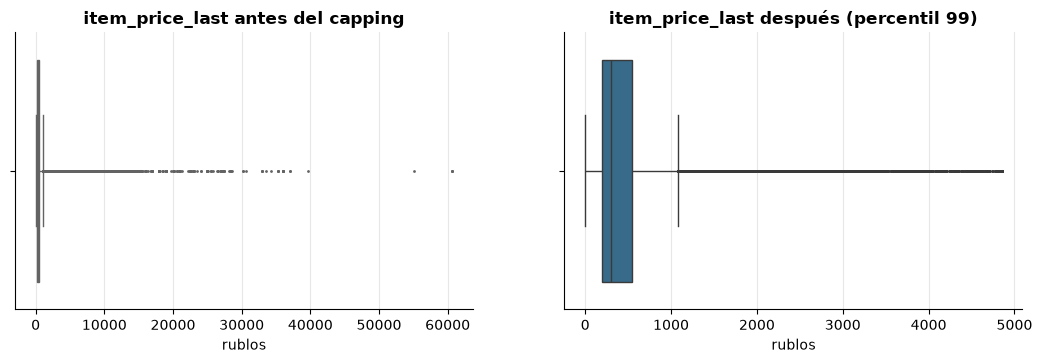

In [21]:
winsor = Winsorizer(capping_method="quantiles", tail="right", fold=0.01, variables=pf.OUTLIER_VARS).fit(imp_train)
capped = winsor.transform(imp_train)
print(f"Límite aprendido: {winsor.right_tail_caps_['item_price_last']:,.0f} rublos · "
      f"máximo antes {price.max():,.0f} → después {capped.item_price_last.max():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
sample = price.sample(200_000, random_state=RANDOM_STATE)
sns.boxplot(x=sample, ax=axes[0], color=COLOR_MUTED, fliersize=1)
axes[0].set(title="item_price_last antes del capping", xlabel="rublos")
sns.boxplot(x=capped.item_price_last.loc[sample.index], ax=axes[1], color=COLOR_MAIN, fliersize=1)
axes[1].set(title="item_price_last después (percentil 99)", xlabel="rublos")
save_fig(fig, "p2_02d_outliers_precio")
plt.show()
del Xtr_e, imp_train, price, sample  # ya no se necesitan (se continúa con `capped`)

**Criterio de selección.** El objetivo ya está acotado: solo el 0.71 % de los pares-mes superaba las 20 unidades y el 0.057 % tenía venta neta negativa; el recorte a [0, 20] los lleva al rango que evalúa Kaggle. En el precio, las reglas IQR son demasiado agresivas para una distribución tan sesgada: IQR × 1.5 recortaría el 13.1 % de las filas (todo lo que cuesta más de 1,078 rublos, es decir, consolas y videojuegos nuevos, que son ventas legítimas) e IQR × 3 el 6.7 %. Se elige el **percentil 99** (`Winsorizer` con cuantiles, cola derecha): solo afecta al 1 % más extremo y lleva el máximo de 60,626 a 4,849 rublos, quitando el peso de unos pocos productos de lujo sin borrar la diferencia entre productos baratos y caros. Se recorta (*capping*) en lugar de eliminar filas porque cada fila es un par que hay que pronosticar.

### 3.v Transformación de variables numéricas

Los lags y el precio son conteos/montos con muchísimos ceros y una cola larga. Se mide la asimetría
antes y después de `log(x + 1)` (`LogCpTransformer` con `C = 1`, que admite ceros).

In [22]:
log_tf = LogCpTransformer(variables=pf.LOG_VARS, C=1).fit(capped)
logged = log_tf.transform(capped)
skew = pd.DataFrame({"asimetría original": capped[pf.LOG_VARS].skew(),
                     "asimetría con log(x+1)": logged[pf.LOG_VARS].skew()})
skew.loc[["cnt_lag_1", "cnt_lag_12", "item_cnt_lag_1", "cat_cnt_lag_1", "shop_cnt_lag_1",
          "shop_cat_cnt_lag_1", "item_price_last", "pair_age"]]

,asimetría original,asimetría con log(x+1)
cnt_lag_1,9.4790,3.4830
cnt_lag_12,13.9978,5.8618
item_cnt_lag_1,9.6440,3.6346
cat_cnt_lag_1,16.8262,2.9697
shop_cnt_lag_1,2.2494,1.6837
shop_cat_cnt_lag_1,12.4329,2.4698
item_price_last,3.4552,0.4017
pair_age,1.6465,0.7088


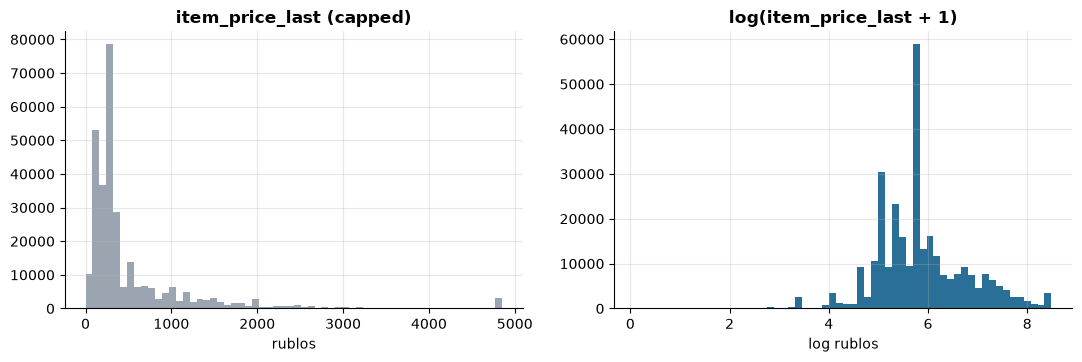

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(capped.item_price_last.sample(300_000, random_state=RANDOM_STATE), bins=60, color=COLOR_MUTED)
axes[0].set(title="item_price_last (capped)", xlabel="rublos")
axes[1].hist(logged.item_price_last.sample(300_000, random_state=RANDOM_STATE), bins=60, color=COLOR_MAIN)
axes[1].set(title="log(item_price_last + 1)", xlabel="log rublos")
save_fig(fig, "p2_02e_transformacion_log")
plt.show()
del capped

**Criterio de selección.** La transformación `log(x + 1)` reduce fuertemente la asimetría de todas las variables de conteo: el lag 1 del par baja de 9.5 a 3.5, el de categoría de 16.8 a 3.0, el de tienda × categoría de 12.4 a 2.5 y el precio de 3.5 a 0.4 (casi simétrico, como muestra el histograma). La asimetría que queda en los lags del par se debe a la masa de ceros, que ninguna transformación monótona elimina. Se elige `log(x + 1)` y no Box-Cox o Yeo-Johnson porque es simple, no necesita estimar parámetros, admite ceros y tiene una interpretación directa (cambios relativos). Para los modelos de árboles es neutra (no cambia el orden de los valores); para el modelo lineal hace que las relaciones sean más lineales y que los valores extremos no dominen los coeficientes.

### 3.vi Escalado de características

Después de codificar, las variables quedan en escalas muy distintas (códigos de tienda 2-59, edad
en meses 0-33, logs 0-3, banderas 0/1, medias codificadas ~0.3).

In [24]:
encoded = mean_enc.transform(onehot.transform(logged))
del logged
to_scale = encoded.drop(columns=pf.DROP_VARS).astype(np.float32)  # float32: la mitad de memoria
del encoded
scaler = StandardScaler().set_output(transform="pandas").fit(to_scale)
scaled = scaler.transform(to_scale)
cols_show = ["shop_id", "item_category_id", "cnt_lag_1", "item_price_last", "item_age", "month", "city", "shop_type_Calle"]
pd.concat({"antes": to_scale[cols_show].agg(["mean", "std", "min", "max"]).T,
           "después (StandardScaler)": scaled[cols_show].agg(["mean", "std", "min", "max"]).T}, axis=1)

antes                        después (StandardScaler)  \
                    mean     std    min     max                     mean   
shop_id          31.2918 17.2830 2.0000 59.0000                   0.0000   
item_category_id 44.8156 14.8644 0.0000 83.0000                  -0.0000   
cnt_lag_1         0.1331  0.3769 0.0000  3.0445                   0.0000   
item_price_last   5.8406  0.9161 0.0953  8.4868                   0.0000   
item_age          8.3294  6.7657 0.0000 26.0000                  -0.0000   
month             5.0430  3.5523 0.0000 11.0000                  -0.0000   
city              0.3046  0.1471 0.1049  0.8143                  -0.0000   
shop_type_Calle   0.0847  0.2785 0.0000  1.0000                  -0.0000   

                                        
                    std     min    max  
shop_id          1.0000 -1.6948 1.6032  
item_category_id 1.0000 -3.0150 2.5689  
cnt_lag_1        1.0000 -0.3531 7.7252  
item_price_last  1.0000 -6.2715 2.8886  
item_age         1.0000 -1.2311 2.6118  
month            1.0000 -1.4197 1.6770  
city             1.0000 -1.3578 3.4660  
shop_type_Calle  1.0000 -0.3043 3.2865

**Criterio de selección.** Antes del escalado las variables vivían en rangos muy distintos: `shop_id` 2-59, edad del producto 0-26, mes 0-11, logs 0-3, medias codificadas 0.1-0.8 y banderas 0/1. Con `StandardScaler` todas quedan con media 0 y desviación 1. Se elige la estandarización (y no min-max) porque varias variables siguen teniendo colas largas y min-max comprimiría casi todos los valores cerca de 0 por culpa de unos pocos extremos. Es imprescindible para el modelo Ridge (la penalización L2 trata a todos los coeficientes por igual, así que las variables deben estar en la misma escala) y no afecta a los modelos de árboles. Los parámetros (media y desviación) se aprenden solo con entrenamiento.

## 4. Proceso final: variables, transformaciones y mecanismos de mapeo

### 4.1 Variables de entrada

El pipeline recibirá filas con **solo tres columnas**: `date_block_num`, `shop_id`, `item_id`
(exactamente lo que trae `test.csv` + el mes 34). Todo lo demás lo genera el pipeline.

| Grupo | Variables | Origen |
|---|---|---|
| Lags del par (autorregresivos) | `cnt_lag_1, 2, 3, 6, 12` | historia mensual, solo meses < m |
| Lags del producto (exógena producto) | `item_cnt_lag_1, 2, 3, 6, 12` | promedio por tienda del producto |
| Lags de grupo (exógenas tienda / categoría) | `cat_cnt_lag_1, 2, 12`, `shop_cnt_lag_1, 2, 12`, `shop_cat_cnt_lag_1, 2, 12` | promedio por par del grupo |
| Precio | `item_price_last` | último precio medio mensual conocido del producto |
| Banderas y antigüedad (exógenas) | `item_is_new`, `pair_is_new`, `item_age`, `pair_age` | primer mes de venta del producto / par |
| Identificadores (exógenas) | `shop_id`, `item_category_id` | fila y catálogo `items.csv` |
| Atributos por mapeo | `city`, `shop_type`, `category_group` | `Mapper` con diccionarios |
| Calendario | `month`, `days_in_month` | `date_block_num` |

`date_block_num` e `item_id` se **eliminan** antes del modelo: el mes absoluto no se puede
extrapolar al mes 34 (la información temporal va en los lags y en `month`) y el id crudo del producto
empeoró el RMSE (sección 2.3); el producto entra por su historia, su categoría y sus banderas.

### 4.2 Transformaciones por variable (en el orden del pipeline)

| # | Proceso | Operación | Variables |
|---|---|---|---|
| 1 | Generación de historia | `SalesHistoryFeatures` (propio) | entrada `date_block_num, shop_id, item_id` |
| 2 | Mapeo | `Mapper` × 3 (propio) | `shop_id → city`, `shop_id → shop_type`, `item_category_id → category_group` |
| 3 | Selección | `DropFeatures` | `date_block_num`, `item_id` |
| 4 | i. Imputación numérica (indicador) | `AddMissingIndicator` | `cnt_lag_1, 2, 3, 6, 12`, `item_price_last` |
| 5 | i. Imputación numérica | `MeanMedianImputer(median)` | los 19 lags + `item_price_last` |
| 6 | ii. Imputación categórica | `CategoricalImputer(fill_value="Missing")` | `city`, `shop_type`, `category_group` |
| 7 | iii. Codificación | `OneHotEncoder(drop_last=True)` | `shop_type` |
| 8 | iii. Codificación | `MeanEncoder(smoothing="auto", unseen="encode")` | `city`, `category_group` |
| 9 | iv. Outliers | `Winsorizer(quantiles, right, fold=0.01)` | `item_price_last` |
| 10 | v. Transformación | `LogCpTransformer(C=1)` | los 19 lags, `item_price_last`, `pair_age` |
| 11 | vi. Escalado | `StandardScaler` | todas las columnas resultantes |
| 12 | Memoria | `DtypeDowncaster` (propio) | todas → `float32` |

Además, **fuera del pipeline de X**: el objetivo `item_cnt_month` se recorta a [0, 20] al construir el
grid, y las predicciones se recortan a [0, 20] al final.

### 4.3 Mecanismos de mapeo

El `Mapper` (mismo patrón que el `QualityOrdinalMapper` visto en clase: lista de `variables` +
diccionario de mapeo, `fit` sin estado y `transform` sobre una copia) usa tres diccionarios
construidos a partir de los catálogos y del trabajo del EDA (`pf.build_mappings`):

In [25]:
for name, mapping in maps.items():
    vals = pd.Series(mapping)
    print(f"{name:15s} {len(mapping):3d} claves -> {vals.nunique():2d} valores · ejemplo: {dict(list(mapping.items())[:3])}")
print("\nVariables por proceso (constantes en predict_future_sales/features.py):")
for label, cols in [("i. imputación numérica", pf.NUM_IMPUTE_VARS), ("i. indicador de faltante", pf.MISSING_INDICATOR_VARS),
                    ("ii. imputación categórica", pf.CAT_VARS), ("iii. one-hot", pf.ONEHOT_VARS),
                    ("iii. mean encoding", pf.MEAN_ENCODE_VARS), ("iv. outliers", pf.OUTLIER_VARS),
                    ("v. log(x+1)", pf.LOG_VARS), ("eliminadas", pf.DROP_VARS)]:
    print(f"- {label} ({len(cols)}): {', '.join(cols)}")
print(f"\nColumnas finales que recibirá el modelo: {scaled.shape[1]}")

city             60 claves -> 31 valores · ejemplo: {0: 'Yakutsk', 1: 'Yakutsk', 2: 'Adigueya'}
shop_type        60 claves ->  5 valores · ejemplo: {0: 'Calle', 1: 'Centro comercial', 2: 'Centro comercial'}
category_group   84 claves -> 18 valores · ejemplo: {40: 'Cine', 76: 'Programas', 55: 'Música'}

Variables por proceso (constantes en predict_future_sales/features.py):
- i. imputación numérica (20): cnt_lag_1, cnt_lag_2, cnt_lag_3, cnt_lag_6, cnt_lag_12, item_cnt_lag_1, item_cnt_lag_2, item_cnt_lag_3, item_cnt_lag_6, item_cnt_lag_12, cat_cnt_lag_1, cat_cnt_lag_2, cat_cnt_lag_12, shop_cnt_lag_1, shop_cnt_lag_2, shop_cnt_lag_12, shop_cat_cnt_lag_1, shop_cat_cnt_lag_2, shop_cat_cnt_lag_12, item_price_last
- i. indicador de faltante (6): cnt_lag_1, cnt_lag_2, cnt_lag_3, cnt_lag_6, cnt_lag_12, item_price_last
- ii. imputación categórica (3): city, shop_type, category_group
- iii. one-hot (1): shop_type
- iii. mean encoding (2): city, category_group
- iv. outliers (1): item_price_last
- 

### 4.4 Conclusiones

1. **Dataset**: grid mensual tienda × producto con ceros (10.9 millones de filas, 85 % ceros), objetivo recortado a [0, 20], partición secuencial 0-26 / 27-33.
2. **Lags**: 1, 2, 3, 6 y 12 a nivel par y producto; 1, 2 y 12 para categoría, tienda y tienda × categoría. Reducen el RMSE ~21 % frente al pronóstico ingenuo y se construyen solo con meses anteriores (sin fuga, verificado con dos pruebas).
3. **Variables exógenas**: tienda (código, ciudad, tipo, historia de la tienda) y producto (categoría, grupo, precio, historia del producto, banderas `item_is_new` / `pair_is_new` y antigüedad), que permiten pronosticar el 48 % del test sin historia propia del par.
4. **Seis procesos**, cada uno elegido con datos: imputación numérica por mediana + indicador; imputación categórica con `Missing` (forzada para la demostración); one-hot + mean encoding + códigos de catálogo; capping del precio en el percentil 99; `log(x + 1)`; `StandardScaler`.
5. El modelo recibirá **40 columnas** numéricas, sin faltantes.

**Siguiente paso:** `03_feature_creation.ipynb` arma estas operaciones como un único `Pipeline` de
scikit-learn y lo guarda en `models/preprocessing_pipeline.pkl`.